In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sys 
sys.path.append("..") 
from lens.raytrace import hit_z, refract_flat, crossing

In [14]:
def exit_flat(m1, n):
    u1 = np.arctan(m1)
    u2 = np.arcsin(n * np.sin(u1))
    return np.tan(u2) # m2

In [15]:
def trace_lens(h, R, n, t):
    z1 = hit_z(h, R)
    m1 = refract_flat(h, R, 1.0, n)
    y2 = h + m1 * (t - z1)
    m2 = exit_flat(m1, n)
    return y2, m2

In [16]:
y2, m2 = trace_lens(6, 25, 1.5, 5)
print(y2, m2)

5.650524820450984 -0.12330341345061471


In [17]:
def cross_axis_back(y2, m2, t):
    return t - (y2 / m2)
print(cross_axis_back(y2, m2, 5))

50.82618325253521


In [18]:
# textbook check for near axis focus
R, t, n = 25, 5, 1.5
f = R / (n - 1)
print(f)
nearaxis_f = f + t * (1 - (1 / n))
print(nearaxis_f)

50.0
51.666666666666664


In [20]:
# when h = 0.01
y21, m21 = trace_lens(0.01, 25, 1.5, 5)
print(y21, m21)
print(cross_axis_back(y21, m21, 5))
# there is no change in focus or near axis focus, coz it does not depend on h

0.009333333558518541 -0.00020000001466666823
51.66666437037029


it matches the textbook check!

In [21]:
for t in [2, 10]:
    print(f"thickness = {t}")
    print("height = 6")
    y2, m2 = trace_lens(6, 25, 1.5, t)
    print(f"y2 = {y2}, m2 = {m2}")
    print(f"crosses the axis at: {cross_axis_back(y2, m2, t)}")
    y21, m21 = trace_lens(0.01, 25, 1.5, t)
    print("height = 0.01")
    print(f"y2 = {y21}, m2 = {m21}")
    print(f"crosses the axis at: {cross_axis_back(y21, m21, t)}")
    f = R / (n - 1)
    print(f"focus = {f}")
    nearaxis_f = f + t * (1 - (1 / n))
    print(f"near-axis focus = {nearaxis_f}")
    print(" ")

thickness = 2
height = 6
y2 = 5.896096714482998, m2 = -0.12330341345061471
crosses the axis at: 49.81778986876542
height = 0.01
y2 = 0.009733333583407434, m2 = -0.00020000001466666823
crosses the axis at: 50.66666434814807
focus = 50.0
near-axis focus = 50.666666666666664
 
thickness = 10
height = 6
y2 = 5.2412383303976275, m2 = -0.12330341345061471
crosses the axis at: 52.506838892151514
height = 0.01
y2 = 0.00866666685037039, m2 = -0.00020000001466666823
crosses the axis at: 53.333331074074
focus = 50.0
near-axis focus = 53.333333333333336
 


when the thickness is more, the focus is the same, but the near-axis focus increases slightly.
also, m2 only changes with height, but the thickness of the glass does not seem to matter - it is identical in every thickness.

In [9]:
h = np.arange(1, 11)
y2, m2 = trace_lens(h, 25, 1.5, 5)
print(np.round(cross_axis_back(y2, m2, 5), 2))

[51.64 51.57 51.46 51.3  51.09 50.83 50.52 50.15 49.73 49.26]


when compared to lesson 14.1, question 5, we can see that the the points where the rays cross the back axis is much closer in the 50s range, but there it was 70s range. this is because, as the rays exit the back, flat surface, they bend away from the normal, which makes them steeper than inside the lens which results in much closer focuses

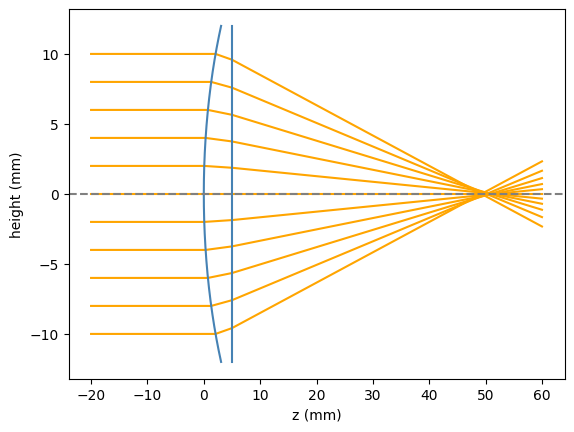

In [10]:
hs = np.linspace(-10, 10, 11)
R, t, n = 25, 5, 1.5
z_end = 60
z = -20
for h in hs:
    z_hit_front = hit_z(h, R)
    z_hit_back = t
    m1 = refract_flat(h, R, 1.0, n)
    y2, m2 = trace_lens(h, R, n, t)
    plt.plot([z, z_hit_front, z_hit_back, z_end], [h, h, y2, y2 + m2 * (z_end - t)], color = "orange")
ys = np.linspace(-12, 12, 200)
plt.plot(R - np.sqrt(R ** 2 - ys ** 2), ys, color = "steelblue")
plt.plot([t, t], [-12, 12], color = "steelblue")
plt.axhline(color = "grey", linestyle = "--")
plt.xlabel("z (mm)")
plt.ylabel("height (mm)")
plt.show()

In [23]:
hss = np.linspace(-10, 10, 1001)
y2, m2 = trace_lens(hss, 25, 1.5, 5)
sensors = np.linspace(40, 55, 151)
spot_sizes = []
for z in sensors:
    y_sensor = y2 + m2 * (z - 5) # positions
    spot_sizes.append(np.sqrt(np.mean(y_sensor ** 2)))
spot_sizes = np.array(spot_sizes)
best = np.argmin(spot_sizes)
print(sensors[best], spot_sizes[best]) # best spot size's position and best spot size

50.2 0.07652434705479157


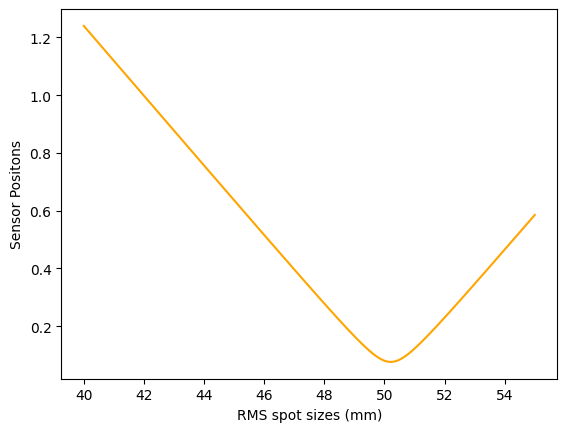

In [24]:
plt.plot(sensors, spot_sizes, color = "orange")
plt.xlabel("RMS spot sizes (mm)")
plt.ylabel("Sensor Positons")
plt.show()

In [25]:
z_textbook = 25 / (1.5 - 1) + 5 * (1 - 1 / 1.5)  # near-axis focus = 51.67
y_textbook = y2 + m2 * (z_textbook - 5)
spot_textbook = np.sqrt(np.mean(y_textbook ** 2))
print("textbook focus:", z_textbook, "mm, RMS spot =", spot_textbook, "mm")

textbook focus: 51.666666666666664 mm, RMS spot = 0.19219209144442312 mm


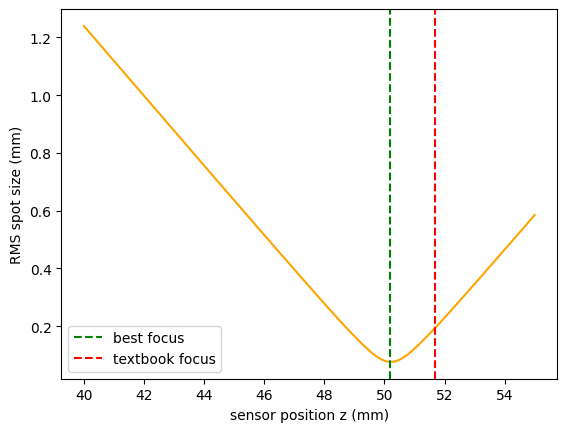

In [27]:
plt.plot(sensors, spot_sizes, color="orange")
plt.axvline(sensors[best], color="green", linestyle="--", label="best focus")
plt.axvline(z_textbook, color="red", linestyle="--", label="textbook focus")
plt.xlabel("sensor position z (mm)")
plt.ylabel("RMS spot size (mm)")
plt.legend()
plt.show()

the textbook formula only describes the near-axis rays, so it puts the sensor where they meet and ignores the edge rays. the ray tracer finds the place that’s best for all of them.